# NASDAQ-100 news propagation: end-to-end demo

This notebook runs the project on the **real data** with the **final model**: the GAT + LSTM at the
tuned configuration T1 (`configs/gat_lstm.yaml`), seed 42, the run whose predictions the report uses.

1. **Load** prices, labels, FinBERT news features and the company graph.
2. **Split** into the five walk-forward folds shared by every model.
3. **Features and graph** for one fold, fitted on its training window only.
4. **Train** the model on that fold and check it reproduces the official predictions.
5. **Predict** and score the held-out half-year.
6. **Trace one prediction** through the graph's attention to the neighbours' news (task 2.10).
7. **The headline result** across all folds: price only, + news, + graph.
8. **Replay** the best verified single window (2022, 5-day development checkpoint), labelled separately.

**Before running:** set up the environment from the README, and point `NDX_DATA_DIR` at the team's
data folder (see `data/README.md`). Running every cell takes about 1.5 minutes on a laptop CPU, most of
it in step 4.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

cwd = Path.cwd()
repo = next((p for p in (cwd, *cwd.parents) if (p / "configs/gat_lstm.yaml").is_file()), None)
if repo is None:
    raise RuntimeError("Open the notebook from inside the nasdaq100-news-graph checkout")
if str(repo) not in sys.path:
    sys.path.insert(0, str(repo))

from src.core.paths import data_dir  # noqa: E402  (after the repo is on the path)

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm, imported by a dependency
pd.set_option("display.precision", 3)

DATA = data_dir()
needed = ["prices", "labels", "news_features", "edges", "article_tickers",
          "predictions/gat_lstm", "predictions/lstm_news", "predictions/lstm_price"]
missing = [n for n in needed if not (DATA / f"{n}.parquet").is_file()]
if missing:
    raise FileNotFoundError(
        f"{DATA} lacks {missing}. This demo needs the real artifacts: set NDX_DATA_DIR to the "
        "team's data folder (data/README.md). The synthetic fixtures are not enough.")
print(f"Data directory: {DATA}")

Data directory: /Users/nonladapream/nasdaq100-news-graph/data


## 1 · Load the data

`load_panel` assembles the inputs every model shares (`src/models/panel.py`): daily prices and
technical indicators, the up/down labels, and per company-day FinBERT news features. Membership is
historical, so a company counts only on days it was in the index (no survivorship bias).

In [2]:
from src.core.io import read_table
from src.models.panel import load_panel

panel = load_panel()
edges = read_table("edges")

period = (panel.days >= "2019-01-01") & (panel.days <= "2023-12-31")
in_index = panel.in_index[period]
has_news = panel.news[period][:, :, 0] > 0
pd.Series({
    "trading days, 2019-2023": int(period.sum()),
    "companies ever in the index": int(panel.in_index.any(axis=0).sum()),
    "in-index company-days": int(in_index.sum()),
    "  with news that day": f"{has_news[in_index].mean():.1%}",
    "  up next day (1d base rate)": f"{np.nanmean(panel.labels[1][period][in_index]):.1%}",
}).to_frame("value")

,value
"trading days, 2019-2023",1258
companies ever in the index,157
in-index company-days,128519
with news that day,49.6%
up next day (1d base rate),52.2%


## 2 · Walk-forward folds

Every model is scored on the same five folds (`configs/walk_forward.yaml`): train on 504 trading
days, skip a 5-day embargo (the longer horizon), test on the next 126. Splits are contiguous in
time and never random.

In [3]:
from src.models.train import folds_for

folds = folds_for(panel)
pd.DataFrame([{
    "fold": f.index,
    "train": f"{f.train[0].date()} to {f.train[-1].date()}",
    "test": f"{f.test[0].date()} to {f.test[-1].date()}",
    "train days": len(f.train), "test days": len(f.test),
} for f in folds]).set_index("fold")

,train,test,train days,test days
fold,,,,
0,2019-01-02 to 2020-12-30,2021-01-08 to 2021-07-09,504,126
1,2019-07-03 to 2021-07-01,2021-07-12 to 2022-01-06,504,126
2,2020-01-02 to 2021-12-30,2022-01-07 to 2022-07-11,504,126
3,2020-07-02 to 2022-07-01,2022-07-12 to 2023-01-09,504,126
4,2020-12-31 to 2022-12-30,2023-01-10 to 2023-07-12,504,126


## 3 · Features and graph for one fold

The rest of the demo uses **fold 4** (test window January to July 2023), which holds the worked
example in step 6. Every scaling statistic, the PCA of the FinBERT embeddings, and the `comention`
and `corr` edge weights come from the fold's training window only. On a day without news the news
features are exactly 0 and `has_news` is 0, so "no coverage" stays distinct from neutral news.

In [4]:
from src.core.config import load_config
from src.models.train import fold_inputs

config = load_config("gat_lstm.yaml")
fold = folds[4]
edge_types, features, graph = fold_inputs(panel, edges, fold, config)

groups = {
    "price indicators": [n for n in features.names if n in config["features"]["price"]],
    "window complete flag": [n for n in features.names if n == "has_full_window"],
    "news scalars": [n for n in features.names if n in config["features"]["news"]],
    "FinBERT embedding (PCA)": [n for n in features.names if n.startswith("emb_pca_")],
}
print(f"{len(features.names)} features per company-day, {config['window_days']}-day look-back window")
for name, cols in groups.items():
    print(f"  {name:24s} {len(cols):3d}  {', '.join(cols[:6])}{' ...' if len(cols) > 6 else ''}")

e = edges[edges["fold"].isin([fold.index, -1])]
pd.DataFrame({
    "pairs": e.groupby("edge_type").size() // 2,
    "companies": e.groupby("edge_type")["dst"].nunique(),
    "median weight": e.groupby("edge_type")["weight"].median(),
}).loc[list(edge_types)]

74 features per company-day, 20-day look-back window
  price indicators           6  ret_1d, volatility_20d, rsi_14, macd, macd_signal, volume_z_20d
  window complete flag       1  has_full_window
  news scalars               3  has_news, sentiment, confidence
  FinBERT embedding (PCA)   64  emb_pca_0, emb_pca_1, emb_pca_2, emb_pca_3, emb_pca_4, emb_pca_5 ...


,pairs,companies,median weight
edge_type,,,
sector,940,169,1.000
comention,756,135,0.004
corr,831,120,0.226


## 4 · Train the final model

Configuration T1 from the tuning pass (task 3.12): batches of 8 trading days, learning rate 1e-3,
hidden size 64, 4 attention heads, dropout 0.1. The last 51 training days are held out (behind
the embargo) for early stopping on validation within-day AUC and for choosing the up/down
threshold. The test window is never used for any choice.

Seed 42 is the run behind the official predictions, so retraining here reproduces them: exactly
on the machine that produced them, and up to tiny floating-point differences on another CPU. The
check below compares every probability and the within-day AUC.

In [5]:
import time

from src.models.ladder_report import within_day_auc
from src.models.train import train_fold

for key in ("train", "encoder", "gat"):
    print(f"{key:8s}", config[key])

horizon = 1
start = time.perf_counter()
predictions, info, fitted = train_fold(panel, edges, fold, horizon, config, return_model=True,
                                       log=lambda *_: None)
print(f"\nTrained in {time.perf_counter() - start:.0f} s: {info['epochs']} epochs, best checkpoint at "
      f"step {info['best_step']} (validation within-day AUC {info['best_val_within_day_auc']:.3f})")

official = read_table("predictions", DATA / "predictions/gat_lstm.parquet")
official = (official[(official["horizon"] == horizon) & (official["fold"] == fold.index)]
            .sort_values(["date", "ticker"]).reset_index(drop=True))
assert predictions[["date", "ticker"]].equals(official[["date", "ticker"]]), "different rows"
new_p, off_p = predictions["p_up"].to_numpy(np.float32), official["p_up"].to_numpy()
# Bit-identical only on the machine that wrote the official file: on another CPU the
# floating-point accumulation during training differs slightly. Check the model is the same
# in practice: same ranking quality and near-identical probabilities.
diff = np.abs(new_p - off_p)
corr = np.corrcoef(new_p, off_p)[0, 1]
auc_new, auc_off = within_day_auc(predictions), within_day_auc(official)
print(f"Retrained vs official: max |dP(up)| {diff.max():.4f}, mean {diff.mean():.4f}, "
      f"correlation {corr:.4f}; within-day AUC {auc_new:.4f} vs {auc_off:.4f}")
assert corr > 0.99 and abs(auc_new - auc_off) < 0.001, "retrained model does not match the official one"
if np.array_equal(new_p, off_p):
    print(f"Identical to the official predictions on all {len(official):,} test rows.")
else:
    print(f"Matches the official predictions on all {len(official):,} test rows "
          "up to floating-point differences between machines.")

train    {'epochs': 40, 'batch_days': 8, 'lr': 0.001, 'weight_decay': 0.0001, 'grad_clip': 1.0, 'validation_fraction': 0.1, 'validate_every_steps': 14, 'early_stopping_metric': 'within_day_auc', 'early_stopping_patience': 4}
encoder  {'hidden': 64, 'layers': 1, 'dropout': 0.1}
gat      {'heads': 4, 'edge_types': ['sector', 'comention', 'corr']}

Trained in 37 s: 16 epochs, best checkpoint at step 644 (validation within-day AUC 0.567)
Retrained vs official: max |dP(up)| 0.0587, mean 0.0052, correlation 0.9988; within-day AUC 0.5009 vs 0.5010
Matches the official predictions on all 12,726 test rows up to floating-point differences between machines.


## 5 · Predict and score the held-out half-year

**Within-day AUC** is the headline metric. On each test day it asks whether the model ranks that
day's risers above its fallers, then averages over days. That matches the research question, which
is about companies relative to each other, not about calling the whole market. Accuracy is shown
next to the base rate (always predicting "up").

In [6]:
from src.models.train import fold_report

m = fold_report(predictions, info)
display(pd.Series({
    "within-day AUC (headline)": m["within_day_auc"], "fold AUC": m["auc"],
    "threshold (chosen on validation)": m["threshold"], "accuracy": m["accuracy"],
    "base rate (always up)": m["base_rate"], "MCC": m["mcc"],
}).to_frame(f"fold {fold.index}, {horizon}d"))

day = pd.Timestamp("2023-05-17")
ranked = predictions[predictions["date"] == day].sort_values("p_up", ascending=False)
print(f"{day.date()}: the model's five most and least likely risers (y_true = realised)")
pd.concat([ranked.head(5), ranked.tail(5)])[["ticker", "p_up", "y_true"]].reset_index(drop=True)

,"fold 4, 1d"
within-day AUC (headline),0.501
fold AUC,0.504
threshold (chosen on validation),0.054
accuracy,0.523
base rate (always up),0.524
MCC,-0.010


2023-05-17: the model's five most and least likely risers (y_true = realised)


,ticker,p_up,y_true
0,SGEN,0.913,1
1,REGN,0.817,0
2,BIIB,0.744,0
3,EXC,0.738,1
4,AZN,0.732,0
5,ADBE,0.222,1
6,PANW,0.222,0
7,INTU,0.186,1
8,ANSS,0.171,1
9,CRWD,0.160,1


## 6 · Trace one prediction through the graph

The worked example from task 2.10: **SGEN (Seagen) on 17 May 2023**. SGEN had no news of its own
that day, so whatever the graph adds comes from its neighbours.

`explain_days` recomputes each prediction with the graph signal removed, overall and one edge type
at a time. The difference is how much the graph moved the prediction. The attention weights then
show *which* neighbours it listened to. Attention is a softmax that sums to 1 for every company and
edge type, so on its own it says nothing about *how much* the graph mattered. That is why the
contribution is shown beside it.

In [7]:
from src.models.attention import explain_days

contrib, incoming = explain_days(fitted, panel, panel.day_index([day]))
row = contrib[contrib["ticker"] == "SGEN"].iloc[0].copy()
row["fold"] = fold.index
sgen_edges = incoming[incoming["dst"] == "SGEN"].reset_index(drop=True)

pd.Series({
    "P(up)": row["p_up"], "P(up) without the graph": row["p_up_no_graph"],
    "realised": "up" if row["y_true"] == 1 else "down", "own news that day": bool(row["has_news"]),
    "graph's push on the logit": row["graph_logit"],
    **{f"  via {t} ({int(row[f'in_degree_{t}'])} edges)": row[f"graph_logit_{t}"] for t in edge_types},
}).to_frame("SGEN, 17 May 2023")

,"SGEN, 17 May 2023"
P(up),0.913
P(up) without the graph,0.49
realised,up
own news that day,False
graph's push on the logit,2.392
via sector (6 edges),0.163
via comention (1 edges),1.973
via corr (8 edges),0.194


Next, the neighbours behind it, with their news over SGEN's 20-day input window. An edge passes on
the neighbour's LSTM state, which summarises that whole window. Headlines are shown when NLP's raw
article files are in `<data>/raw/` (as on the shared drive). Otherwise each article carries its
company-day mean FinBERT sentiment, which is what the model reads.

In [8]:
from src.nlp import interpret
from src.nlp.examples import figure

days = interpret.window_days(panel.days, day, config["window_days"])
order = interpret.type_order(row, sgen_edges["edge_type"].unique())
neighbours = interpret.top_neighbours(sgen_edges, order)
links = read_table("article_tickers")
ids = links[links["ticker"].isin(set(neighbours["src"])) & links["date"].isin(days)]["article_id"]

raw = DATA / "raw"
with_titles = (raw / "article_features.parquet").is_file() and (raw / "fnspid_filtered.csv").is_file()
if with_titles:  # article-level sentiment and headlines (reads a 1 GB CSV: about a minute)
    t = interpret.trace(row, sgen_edges, links, days, interpret.article_info(ids))
else:
    news = read_table("news_features", columns=["date", "ticker", "has_news", "sentiment"])
    daily = news[news["has_news"]].set_index(["ticker", "date"])["sentiment"]
    t = interpret.trace(row, sgen_edges, links, days)
    t["evidence"]["sentiment"] = daily.reindex(
        pd.MultiIndex.from_arrays([t["evidence"]["src"], t["evidence"]["date"]])).to_numpy()

display(Markdown(interpret.format_trace(t, max_articles=3 if with_titles else 0)))

## SGEN on 2023-05-17, 1-day horizon (fold 4)

- P(up) **0.913**, without the graph 0.490; realised label: up; own news that day: no
- Graph logit +2.392, of which within-day (changes the ranking) +2.712
- News window: 2023-04-20 to 2023-05-17 (20 trading days)

### comention: graph logit +1.973 (1 incoming edges, uniform attention 1.000)

- **VRTX** -> SGEN: attention 1.000, edge weight 0.003, 61 articles in window on 16 days
  - mean headline sentiment +0.034

### corr: graph logit +0.194 (8 incoming edges, uniform attention 0.125)

- **DXCM** -> SGEN: attention 0.162, edge weight 0.086, 31 articles in window on 14 days
  - mean headline sentiment +0.158
- **VRTX** -> SGEN: attention 0.139, edge weight 0.278, 61 articles in window on 16 days
  - mean headline sentiment +0.034
- **CRWD** -> SGEN: attention 0.131, edge weight 0.104, 69 articles in window on 19 days
  - mean headline sentiment +0.130

### sector: graph logit +0.163 (6 incoming edges, uniform attention 0.167)

- **AMGN** -> SGEN: attention 0.182, edge weight 1.000, 76 articles in window on 18 days
  - mean headline sentiment -0.127
- **BIIB** -> SGEN: attention 0.165, edge weight 1.000, 45 articles in window on 17 days
  - mean headline sentiment +0.209
- **VRTX** -> SGEN: attention 0.164, edge weight 1.000, 61 articles in window on 16 days
  - mean headline sentiment +0.034


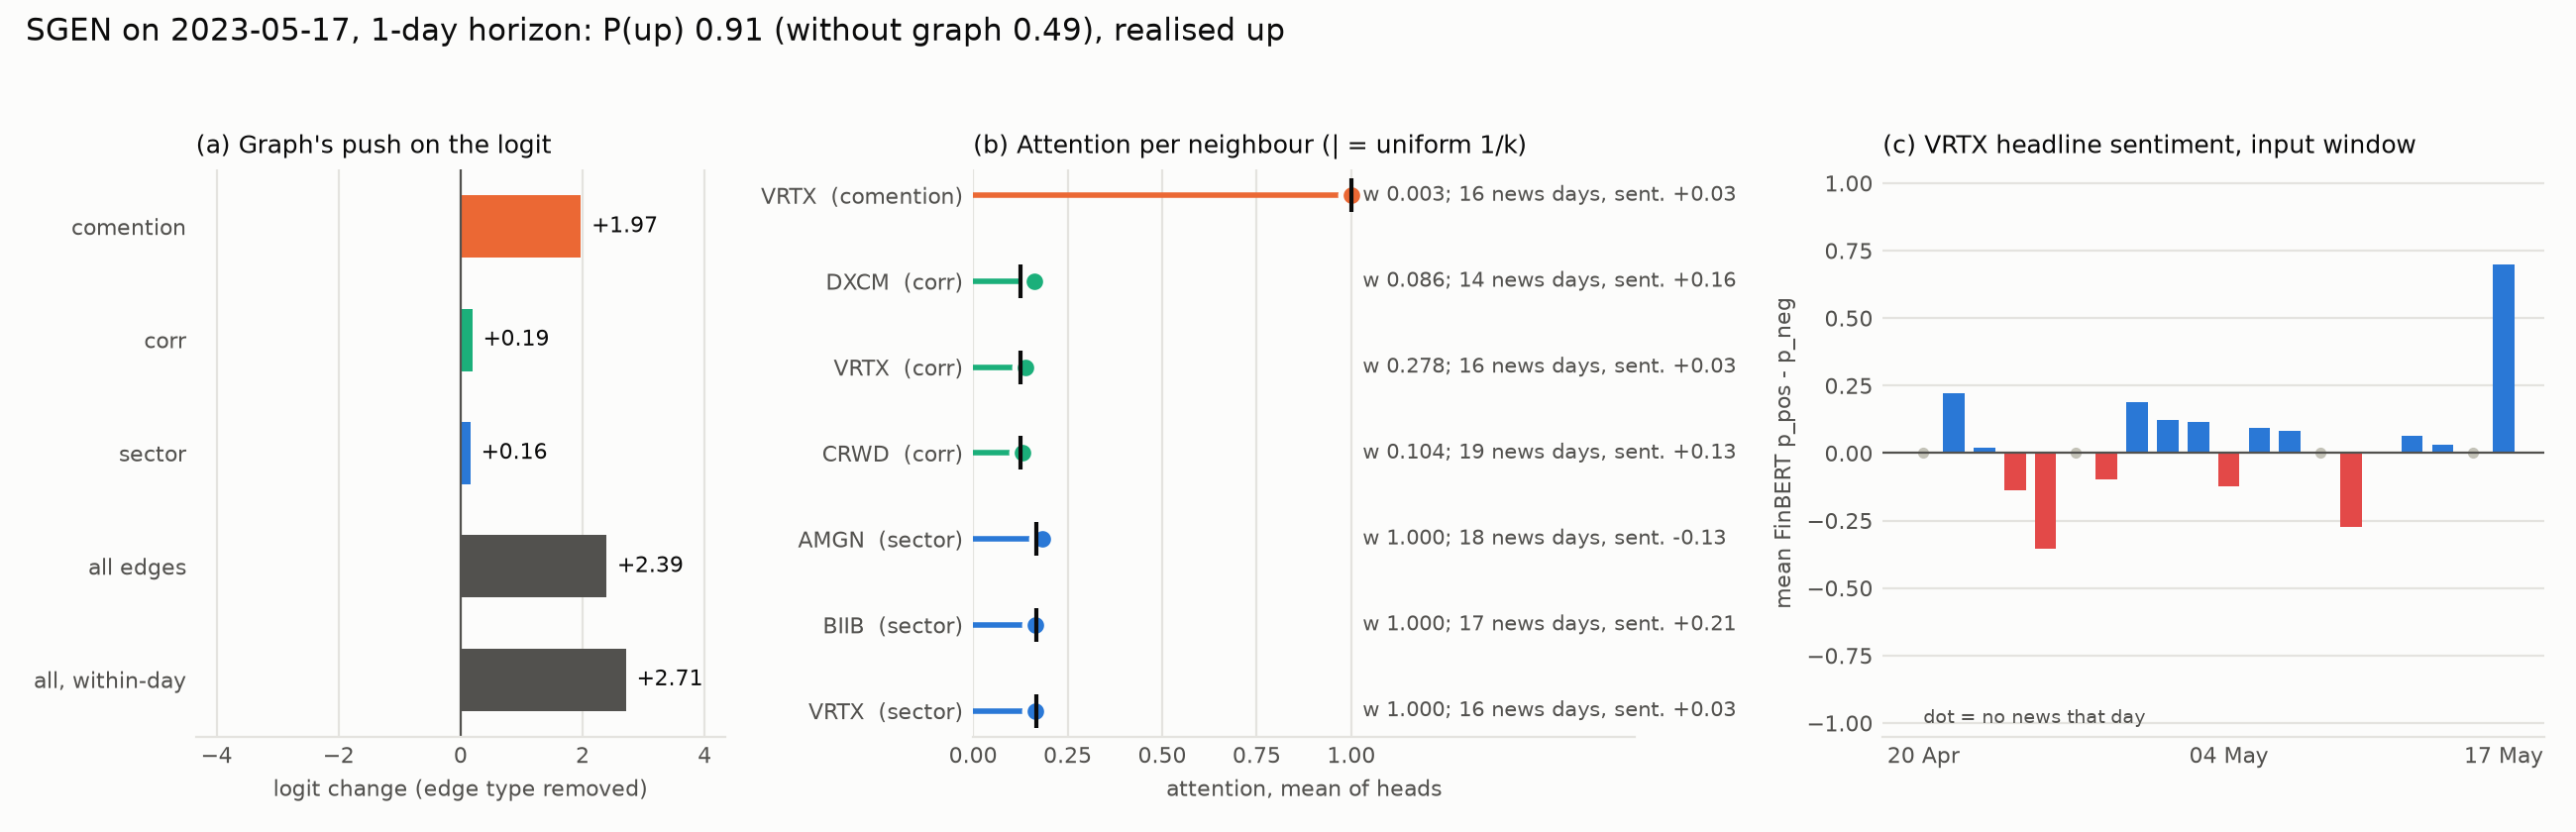

In [9]:
import tempfile

png = Path(tempfile.gettempdir()) / "demo_trace_sgen.png"
figure(t, png)
Image(filename=png)

**How to read it.** Almost all of the push (+2.0 of +2.4 on the logit) comes through one
`comention` edge from VRTX (Vertex), SGEN's only edge of that type. Being the only one, it gets
attention 1.0 by construction, although its weight (0.003) is close to the weakest in the graph.
This is the mechanism the project tests in its plainest form: a company with no coverage of its
own receives a signal from a related one. It also shows the mechanism's weakness. The example was
picked for its large graph contribution, so it shows how propagation works, not how often it
helps (`results/interpretability/README.md`).

## 7 · The headline result across all folds

The comparison the conclusion rests on is a ladder in which each step adds one component, with
everything else held fixed. Baseline 5 is the same LSTM on prices only. Baseline 6 adds the news
features. The proposed model adds the graph. All three are trained by the same code at the same
settings and seed, on the same folds and rows. These are the official predictions.

In [10]:
from src.models.ladder_report import within_day_auc

ladder = {"B5 price only": "lstm_price", "B6 + news": "lstm_news", "proposed + graph": "gat_lstm"}
scores = {}
for label, name in ladder.items():
    p = read_table("predictions", DATA / f"predictions/{name}.parquet")
    scores[label] = p.groupby(["horizon", "fold"]).apply(within_day_auc, include_groups=False)
by_fold = pd.DataFrame(scores)
table = by_fold.groupby("horizon").mean()
table["news step"] = table["B6 + news"] - table["B5 price only"]
table["graph step"] = table["proposed + graph"] - table["B6 + news"]
table["graph step > 0 (folds)"] = (
    (by_fold["proposed + graph"] - by_fold["B6 + news"]).gt(0).groupby("horizon").sum().astype(str) + " / 5")
table.index = [f"{h} day" for h in table.index]
table.round(3)

,B5 price only,B6 + news,proposed + graph,news step,graph step,graph step > 0 (folds)
1 day,0.499,0.505,0.509,0.006,0.004,4 / 5
5 day,0.481,0.507,0.499,0.026,-0.008,1 / 5


**Reading.** News adds a small amount of cross-sectional signal. Graph propagation does not add a
detectable amount:
- **1 day:** the graph step is +0.004 at this seed, but across three seeds it is positive in only 9
  of 15 fold-seeds.
- **5 days:** the graph step is negative.
- **Significance:** the report's test, on MCC, finds no difference between the proposed model and
  Baseline 6 at either horizon.

Baseline 5 sits below 0.5 at 5 days, so part of the 5-day news step is plausibly news keeping the
model off Baseline 5's below-chance bet, rather than new signal. The report has the three-seed
ablations, the significance tests and the backtest.

## 8 · Best verified single window: replay of the 2022 development checkpoint

Steps 4–7 are the official model and folds. This step shows a **different, separately labelled**
result: the strongest single retrospective window from the later development studies
(`experiments/gat_edge_weight_v1`, documented in `experiments/historical_demo_v1/DEMO.md`).

| | Official model (steps 4–7) | This replay |
|---|---|---|
| Inputs | prices + FinBERT news, sector/comention/corr graph | prices only, corr graph |
| Horizon | 1 day (step 5), both in step 7 | 5 days |
| Test window | five folds 2021–2023 | 18 Jul – 30 Dec 2022 (117 days) |
| Fit / validation | 504 days / last 51 | 252 days / 50 days, 5-day gaps |

Nothing is trained here. The cell rebuilds the fold's correlation graph from prices and checks it
equals the saved one, loads the saved checkpoint, runs a forward pass on every test row, checks each
probability against the archived predictions, and recomputes the metrics with the threshold chosen
on validation.

In [11]:
from contextlib import chdir

from experiments.historical_demo_v1.replay import development

with chdir(repo):  # the replay reads its archived files by repo-relative paths
    dev = development()
m = dev["metrics"]
display(pd.Series({
    "test rows / trading days": f"{m['rows']:,} / {m['dates']}",
    "within-day AUC (headline)": round(m["within_day_auc"], 4),
    "accuracy": round(m["accuracy"], 4),
    "majority baseline (same rows)": round(m["majority"], 4),
    "MCC": round(m["mcc"], 4),
    "threshold (chosen on validation)": round(m["threshold"], 4),
    "graph rebuilt exactly (edges)": f"{dev['graph_rebuild_exact']} ({dev['graph_rows']:,})",
    "max |P(up) - archived|": dev["max_probability_delta"],
}).to_frame("2022 H2, 5-day, seed 42"))
pd.DataFrame(dev["split"], index=["first day", "last day", "trading days"]).T

,"2022 H2, 5-day, seed 42"
test rows / trading days,"11,925 / 117"
within-day AUC (headline),0.544
accuracy,0.555
majority baseline (same rows),0.512
MCC,0.111
threshold (chosen on validation),0.42
graph rebuilt exactly (edges),"True (1,492)"
max |P(up) - archived|,0.0


,first day,last day,trading days
fit,2021-04-21,2022-04-19,252
validation,2022-04-27,2022-07-08,50
assessment,2022-07-18,2022-12-30,117


**Reading.** In this window the model ranks 5-day risers above fallers better than chance (within-day
AUC 0.544) and its accuracy beats the majority baseline on the same rows by about 4 points (MCC 0.11).
Keep it in proportion:
- It is **one** retrospective development window, not the official result. The official five-fold
  result is the table in step 7 (within-day AUC about 0.50–0.51).
- The same configuration at seed 43 reached 0.540 here, but in the matching 2023 window it fell to
  0.504 (seed 42) and 0.436 (seed 43): the signal is not stable across periods.
- Its MACD inputs are price differences on split-adjusted closes, so their scale reflects later
  splits; a scale-free version removes the 2023 collapse but does not raise the mean
  (`experiments/macd_scale_v1/report.md`).